## Sample Machine Learning Project (IRIS dataset)
Produced by Singapore Polytechnic

In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

### Step 1: Load Data

In [2]:
# Load the Iris dataset
df = pd.read_csv('iris.csv')
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### Step 2: Summary Statistics
Things you can consider to do
1. initial data inspection
2. checking the data size, data types
3. missing value analysis

In [3]:
# show the dataset basic information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [4]:
# Display basic statistics
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [5]:
# Display the class distribution
print(df['target'].value_counts())

target
0    50
1    50
2    50
Name: count, dtype: int64


In [6]:
# Check Missing Values
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

This means there is no missing values, great!

### Step 3: Exploratory Data Analysis
things you can consider to do
1. data cleaning
2. handle missing values
3. handle outliers
4. data visualization

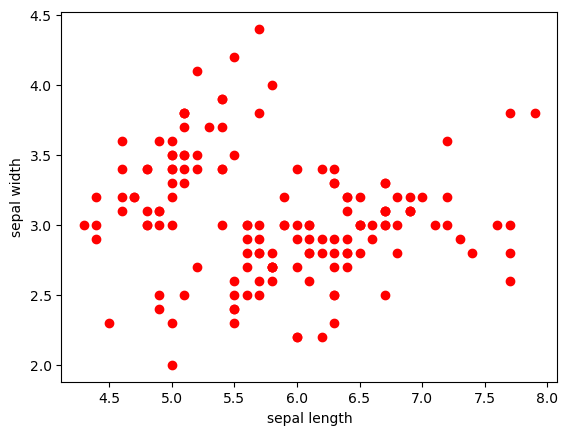

In [7]:
plt.scatter(df['sepal length (cm)'], df['sepal width (cm)'], color='red')
plt.xlabel('sepal length')
plt.ylabel('sepal width')
plt.show()

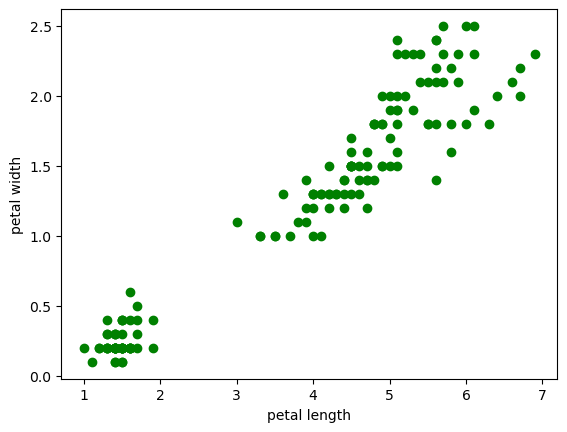

In [8]:
# Scatter plot to show correlation of features
plt.scatter(df['petal length (cm)'], df['petal width (cm)'], color='green')
plt.xlabel('petal length')
plt.ylabel('petal width')
plt.show()

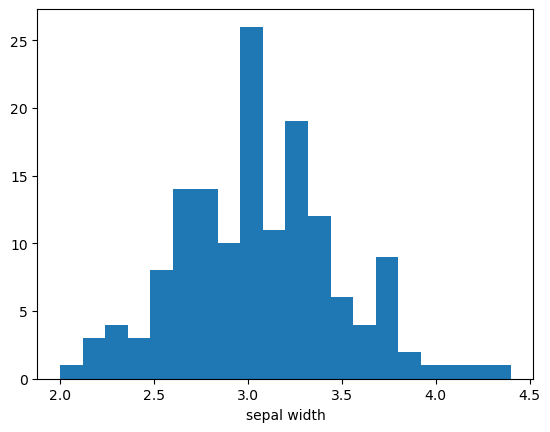

In [9]:
# histogram
plt.hist(df['sepal width (cm)'], bins=20)
plt.xlabel('sepal width')
plt.show()

### Step 4: Machine Learning Models
In this step, you can try a few models in sklearn and compare their performance

In [10]:
# Train Test Split
# Split the data into training and testing sets
X = df[['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']]
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [11]:
# Test various models
models = {
    'Logistic Regression': LogisticRegression(max_iter=500),
    'Support Vector Machine': SVC(),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier()
}

for name in models:
    model = models[name]
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='weighted')
    print(f'Model {name} prediction accuracy is {accuracy*100:.1f}%, f1-score is {f1*100:.1f}%')

Model Logistic Regression prediction accuracy is 96.7%, f1-score is 96.6%
Model Support Vector Machine prediction accuracy is 96.7%, f1-score is 96.6%
Model Naive Bayes prediction accuracy is 96.7%, f1-score is 96.6%
Model Random Forest prediction accuracy is 96.7%, f1-score is 96.6%


### Step 5: Hyperparameters Tuning
In this step, we are looking for the best hyperparameter combination in order to optimize the model performance

In [12]:
# Define a function to do model evaluation
def evaluate(model, test_features, test_labels):
    predictions = model.predict(test_features)
    accuracy = 100 * accuracy_score(test_labels, predictions)
    f1 = 100 * f1_score(test_labels, predictions, average='weighted')
    print('Model Performance')
    print('Prediction Accuracy = {:0.1f}%.'.format(accuracy))
    print('Prediction f1-score = {:0.1f}%.'.format(f1))
    return accuracy, f1

In [13]:
# define what are the hyperparameters to tune
para_grid = {
    'n_estimators': [100, 300, 500],
    'min_samples_leaf': [1, 2, 4],
    'min_samples_split': [2, 5, 10],
    'bootstrap': [True, False]
}

rf = RandomForestClassifier()
rf_grid = GridSearchCV(estimator=rf,
                       param_grid=para_grid)

rf_grid.fit(X_train, y_train)

GridSearchCV(estimator=RandomForestClassifier(),
             param_grid={'bootstrap': [True, False],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 300, 500]})

In [14]:
# show the final model performance
best_model = rf_grid.best_estimator_
grid_accuracy = evaluate(best_model, X_test, y_test)

Model Performance
Prediction Accuracy = 96.7%.
Prediction f1-score = 96.6%.


In [15]:
rf_grid.best_params_

{'bootstrap': True,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'n_estimators': 100}

## End Of Example